<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Bar Charts**


Estimated time needed: **30** minutes


In this lab, you will focus on visualizing data.

The dataset will be provided to you in the form of an RDBMS.

You will use SQL queries to extract the necessary data.


## Objectives


In this lab you will perform the following:


-   Visualize the distribution of data

-   Visualize the relationship between two features

-   Visualize the composition of data

-   Visualize comparison of data


## Setup: Working with the Database
**Install the needed libraries**


In [30]:
!pip install pandas

In [31]:
!pip install matplotlib

**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



In [32]:
# Step 1: Download the dataset
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

# Step 2: Import necessary libraries and load the dataset
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
df = pd.read_csv("survey-data.csv")

# Display the first few rows to understand the structure of the data
df.head()


--2026-08-25 01:50:20--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv     100%[===================>] 152.13M  4.03MB/s    in 37s     

2026-08-25 01:50:57 (4.13 MB/s) - ‘survey-data.csv’ saved [159525875/159525875]


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Visualizing Data Distributions


##### 1. Histogram of `ConvertedCompYearly`


Visualize the distribution of yearly compensation (`ConvertedCompYearly`) using a histogram.



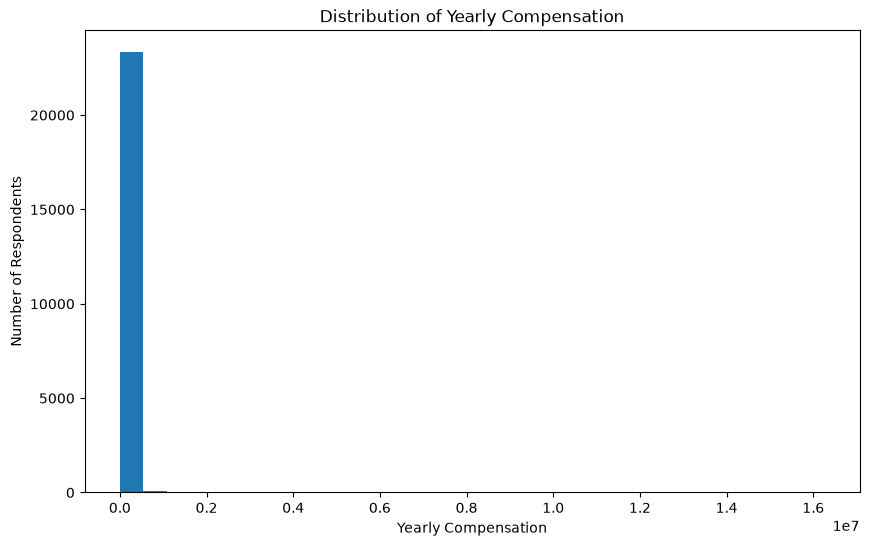

In [33]:
## Write your code here
# Remove missing compensation values
comp_data = df["ConvertedCompYearly"].dropna()

# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(
    comp_data,
    bins=30
)

plt.title("Distribution of Yearly Compensation")
plt.xlabel("Yearly Compensation")
plt.ylabel("Number of Respondents")

plt.show()

##### 2. Box Plot of `Age`


Since `Age` is categorical in the dataset, convert it to numerical values for a box plot.



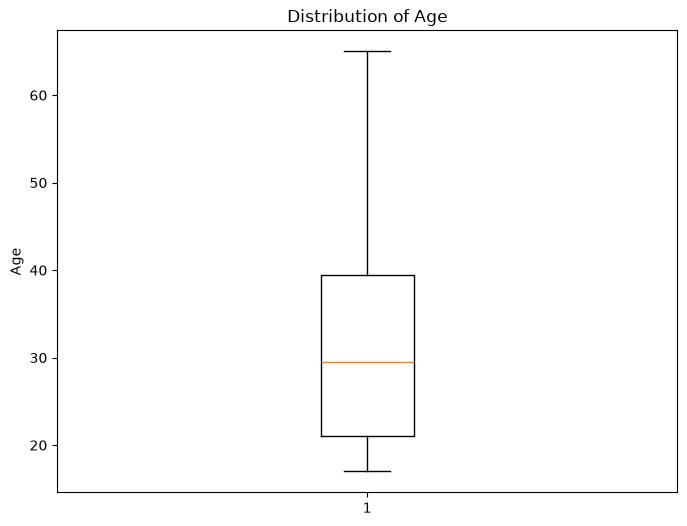

In [34]:
## Write your code here
# Convert Age groups to numerical values
age_mapping = {
    "Under 18 years old": 17,
    "18-24 years old": 21,
    "25-34 years old": 29.5,
    "35-44 years old": 39.5,
    "45-54 years old": 49.5,
    "55-64 years old": 59.5,
    "65 years or older": 65,
    "Prefer not to say": None
}

age_numeric = df["Age"].map(age_mapping).dropna()

# Create box plot
plt.figure(figsize=(8, 6))

plt.boxplot(age_numeric)

plt.title("Distribution of Age")
plt.ylabel("Age")

plt.show()

### Task 2: Visualizing Relationships in Data


##### 1. Scatter Plot of `Age_numeric` and `ConvertedCompYearly`


Explore the relationship between age and compensation.



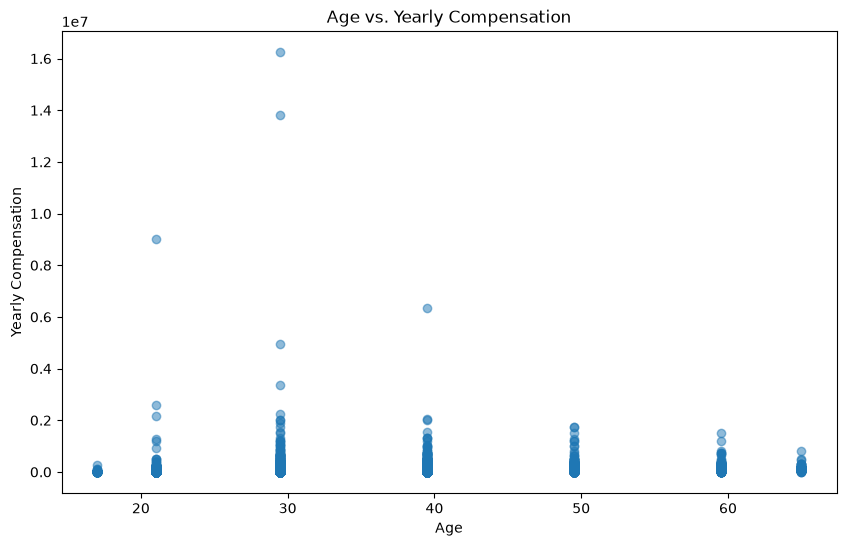

In [35]:
## Write your code here
# Create a dataframe with age and compensation
scatter_data = pd.DataFrame({
    "Age_numeric": df["Age"].map(age_mapping),
    "ConvertedCompYearly": pd.to_numeric(
        df["ConvertedCompYearly"],
        errors="coerce"
    )
}).dropna()

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    scatter_data["Age_numeric"],
    scatter_data["ConvertedCompYearly"],
    alpha=0.5
)

plt.title("Age vs. Yearly Compensation")
plt.xlabel("Age")
plt.ylabel("Yearly Compensation")

plt.show()

##### 2. Bubble Plot of `ConvertedCompYearly` and `JobSatPoints_6` with `Age_numeric` as Bubble Size


Explore how compensation and job satisfaction are related, with age as the bubble size.


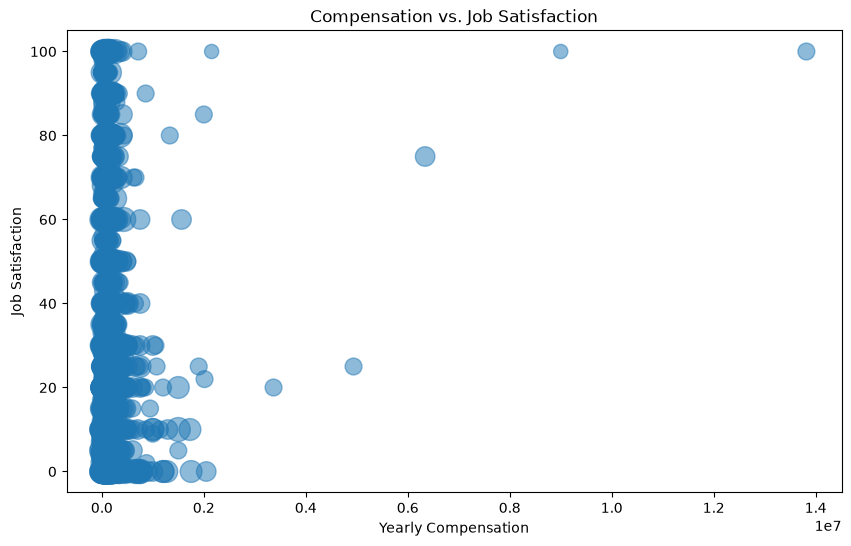

In [36]:
## Write your code here
# Create data for the bubble plot
bubble_data = pd.DataFrame({
    "Age_numeric": df["Age"].map(age_mapping),
    "ConvertedCompYearly": pd.to_numeric(
        df["ConvertedCompYearly"],
        errors="coerce"
    ),
    "JobSatPoints_6": pd.to_numeric(
        df["JobSatPoints_6"],
        errors="coerce"
    )
}).dropna()

# Create bubble plot
plt.figure(figsize=(10, 6))

plt.scatter(
    bubble_data["ConvertedCompYearly"],
    bubble_data["JobSatPoints_6"],
    s=bubble_data["Age_numeric"] * 5,
    alpha=0.5
)

plt.title("Compensation vs. Job Satisfaction")
plt.xlabel("Yearly Compensation")
plt.ylabel("Job Satisfaction")

plt.show()

### Task 3: Visualizing Composition of Data with Bar Charts


##### 1. Horizontal Bar Chart of `MainBranch` Distribution


Visualize the distribution of respondents’ primary roles to understand their professional focus.



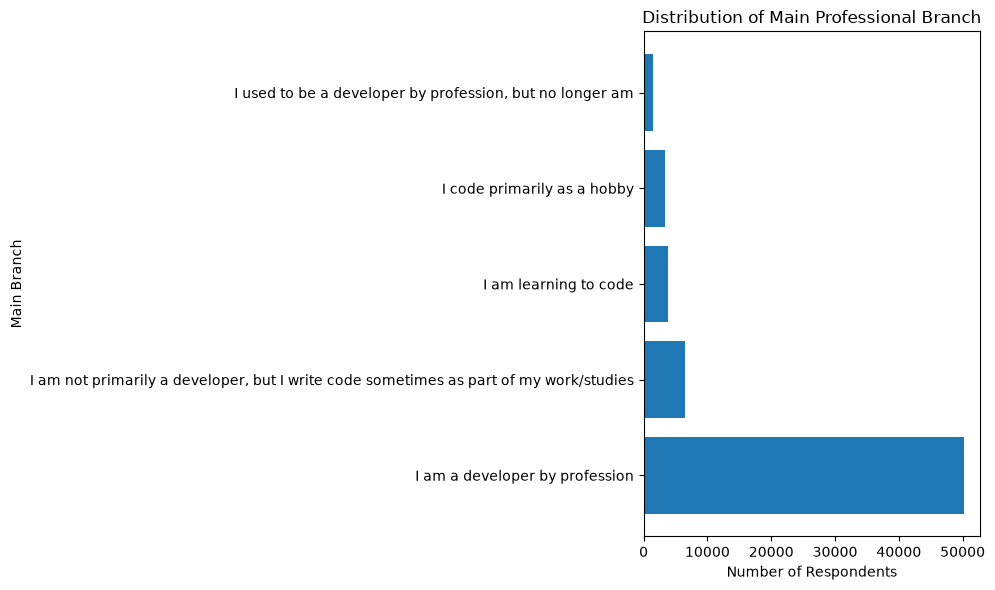

In [37]:
## Write your code here
# Count respondents by MainBranch
mainbranch_counts = df["MainBranch"].dropna().value_counts()

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    mainbranch_counts.index,
    mainbranch_counts.values
)

plt.title("Distribution of Main Professional Branch")
plt.xlabel("Number of Respondents")
plt.ylabel("Main Branch")

plt.tight_layout()
plt.show()

##### 2. Vertical Bar Chart of Top 5 Programming Languages Respondents Want to Work With


Identify the most desired programming languages based on `LanguageWantToWorkWith`.



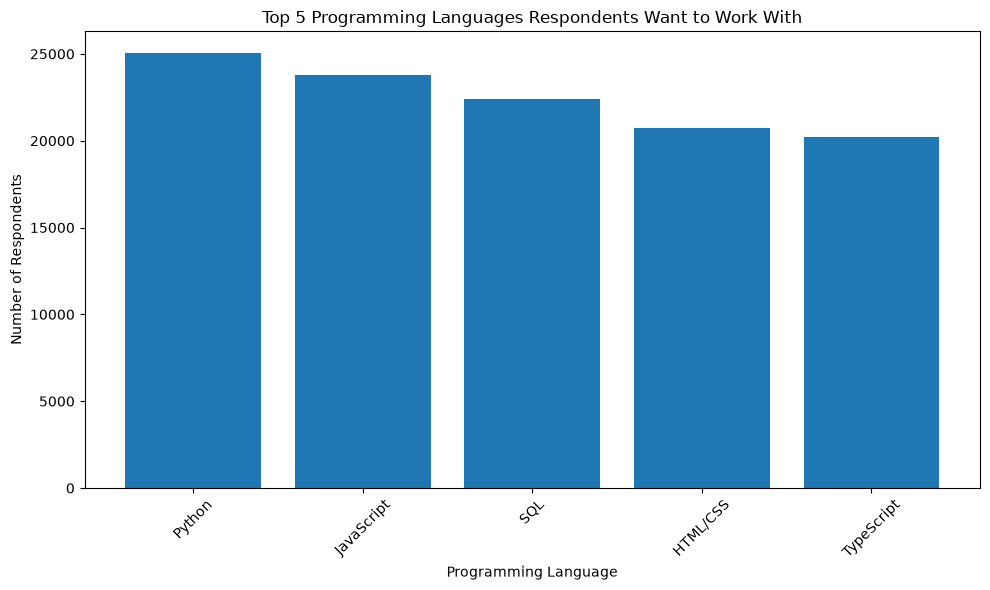

In [38]:
## Write your code here
# Split multiple programming language responses
language_data = df["LanguageWantToWorkWith"].dropna().str.split(";").explode()

# Clean language names
language_data = language_data.str.strip()

# Get the top 5 programming languages
top_languages = language_data.value_counts().head(5)

# Create vertical bar chart
plt.figure(figsize=(10, 6))

plt.bar(
    top_languages.index,
    top_languages.values
)

plt.title("Top 5 Programming Languages Respondents Want to Work With")
plt.xlabel("Programming Language")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

##### 3. Stacked Bar Chart of Median `JobSatPoints_6` and `JobSatPoints_7` by Age Group


Compare job satisfaction metrics across different age groups with a stacked bar chart.


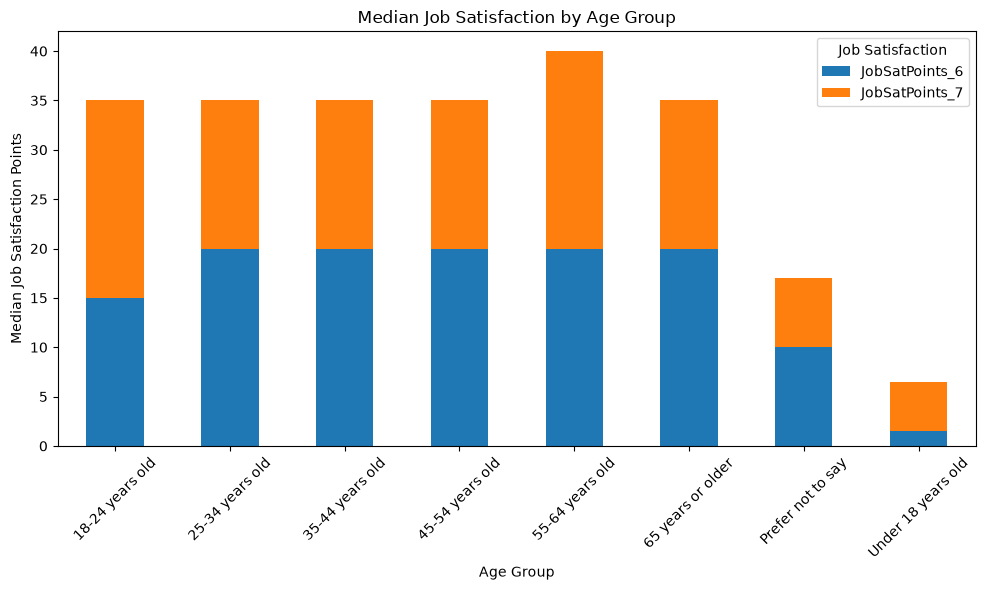

In [39]:
## Write your code here
# Select age and job satisfaction data
sat_data = df[
    ["Age", "JobSatPoints_6", "JobSatPoints_7"]
].copy()

# Convert satisfaction columns to numeric
sat_data["JobSatPoints_6"] = pd.to_numeric(
    sat_data["JobSatPoints_6"],
    errors="coerce"
)

sat_data["JobSatPoints_7"] = pd.to_numeric(
    sat_data["JobSatPoints_7"],
    errors="coerce"
)

# Calculate median satisfaction by age group
sat_summary = (
    sat_data
    .groupby("Age")[["JobSatPoints_6", "JobSatPoints_7"]]
    .median()
)

# Create stacked bar chart
sat_summary.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Median Job Satisfaction by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Median Job Satisfaction Points")
plt.xticks(rotation=45)

plt.legend(
    title="Job Satisfaction"
)

plt.tight_layout()
plt.show()

##### 4. Bar Chart of Database Popularity (`DatabaseHaveWorkedWith`)


Identify the most commonly used databases among respondents by visualizing `DatabaseHaveWorkedWith`.



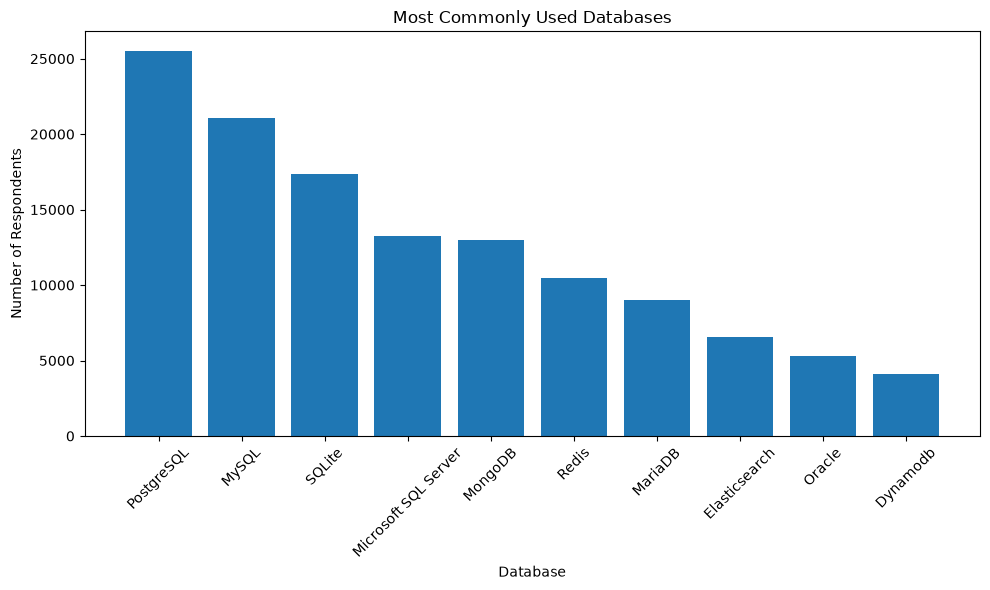

In [40]:
## Write your code here
# Split multiple database responses
database_data = (
    df["DatabaseHaveWorkedWith"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
)

# Count database usage
database_counts = database_data.value_counts().head(10)

# Create bar chart
plt.figure(figsize=(10, 6))

plt.bar(
    database_counts.index,
    database_counts.values
)

plt.title("Most Commonly Used Databases")
plt.xlabel("Database")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Task 4: Visualizing Comparison of Data with Bar Charts


##### 1. Grouped Bar Chart of Median `ConvertedCompYearly` for Different Age Groups


Compare median compensation across multiple age groups with a grouped bar chart.



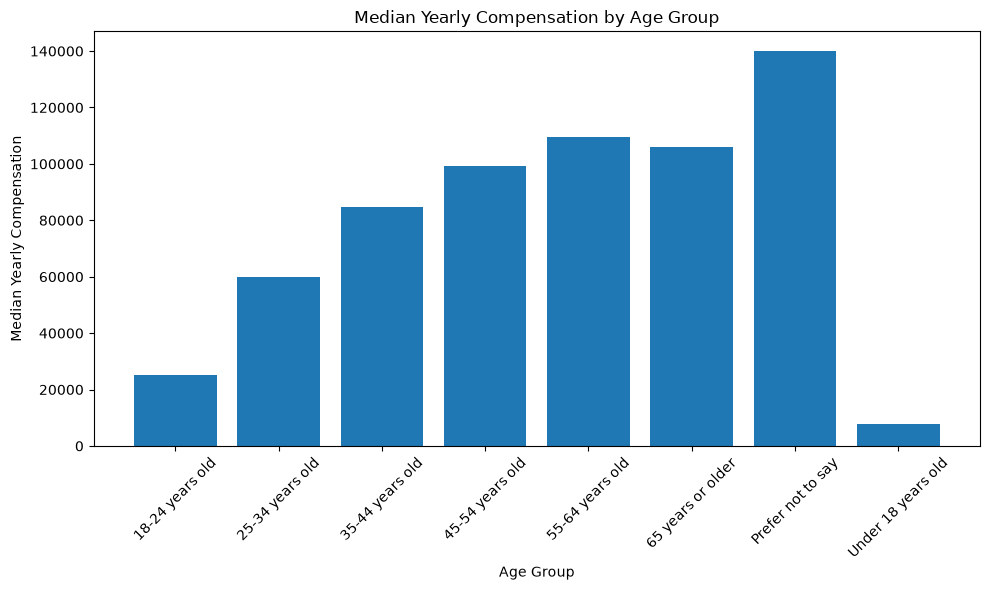

In [41]:
## Write your code here
# Calculate median compensation by age group
age_comp = (
    df.groupby("Age")["ConvertedCompYearly"]
    .median()
    .dropna()
)

# Create grouped bar chart
plt.figure(figsize=(10, 6))

plt.bar(
    age_comp.index,
    age_comp.values
)

plt.title("Median Yearly Compensation by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Median Yearly Compensation")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

##### 2. Bar Chart of Respondent Count by Country


Show the distribution of respondents by country to see which regions are most represented.



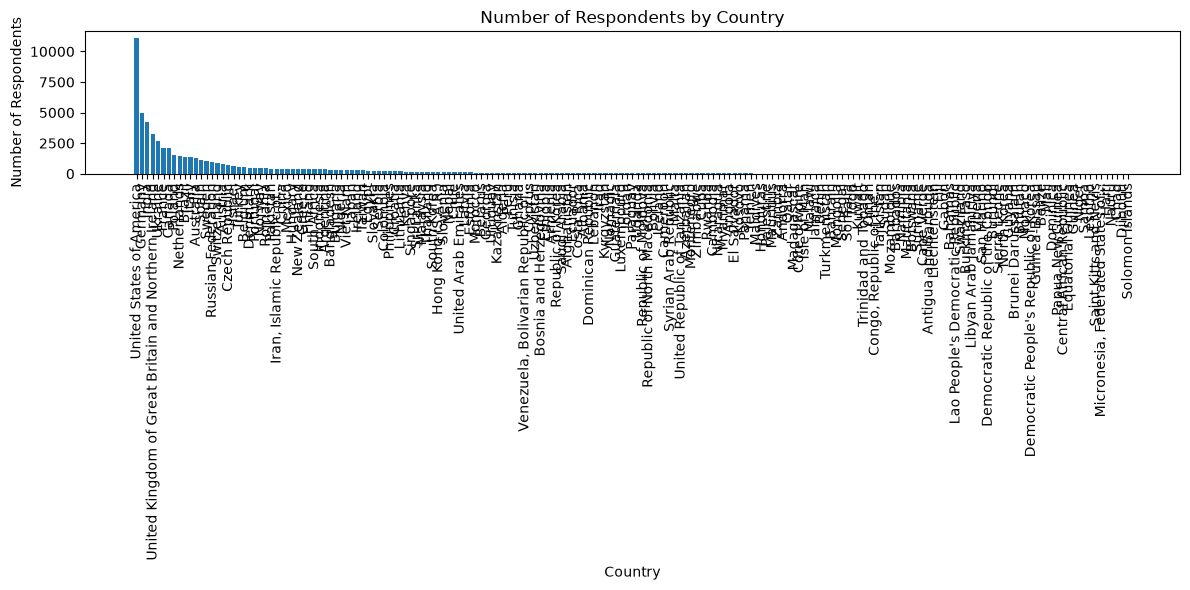

In [42]:
## Write your code here
# Count respondents by country
country_counts = df["Country"].dropna().value_counts()

# Create bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    country_counts.index,
    country_counts.values
)

plt.title("Number of Respondents by Country")
plt.xlabel("Country")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

### Final Step: Review


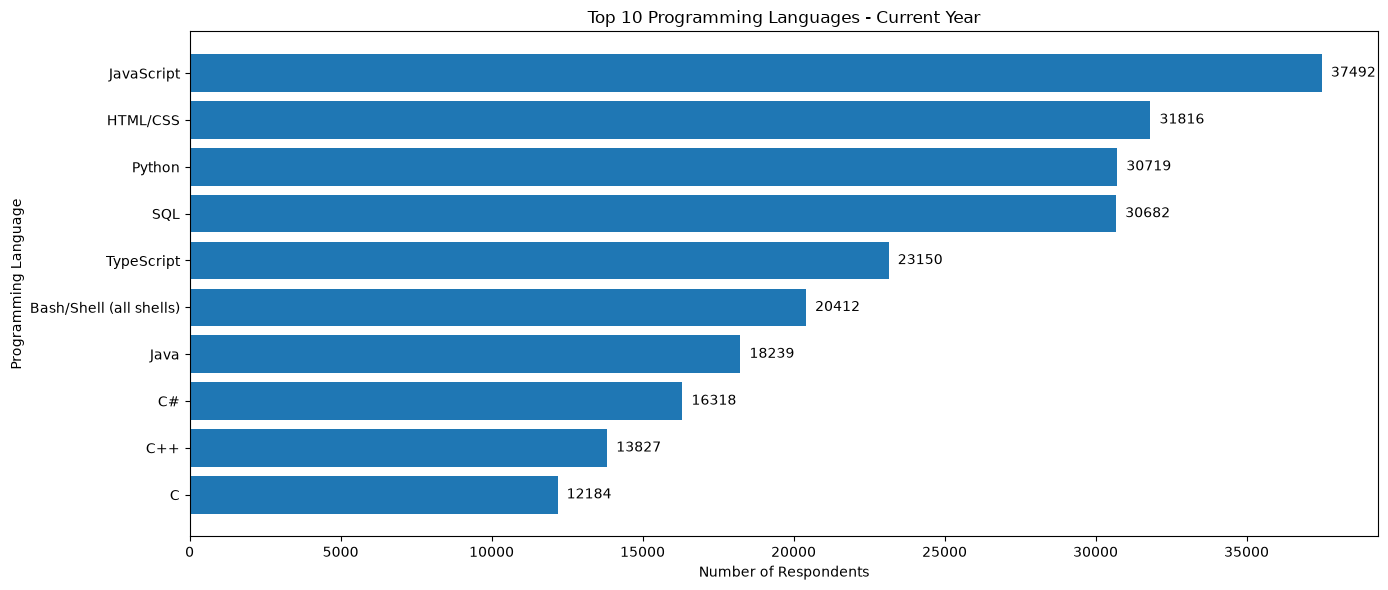

In [56]:
plt.figure(figsize=(14, 6))

bars = plt.barh(
    current_top10.index[::-1],
    current_top10.values[::-1]
)

plt.title("Top 10 Programming Languages - Current Year")
plt.xlabel("Number of Respondents")
plt.ylabel("Programming Language")

# Add data labels
for bar in bars:
    plt.text(
        bar.get_width() + 300,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center",
        ha="left"
    )

plt.tight_layout()
plt.show()

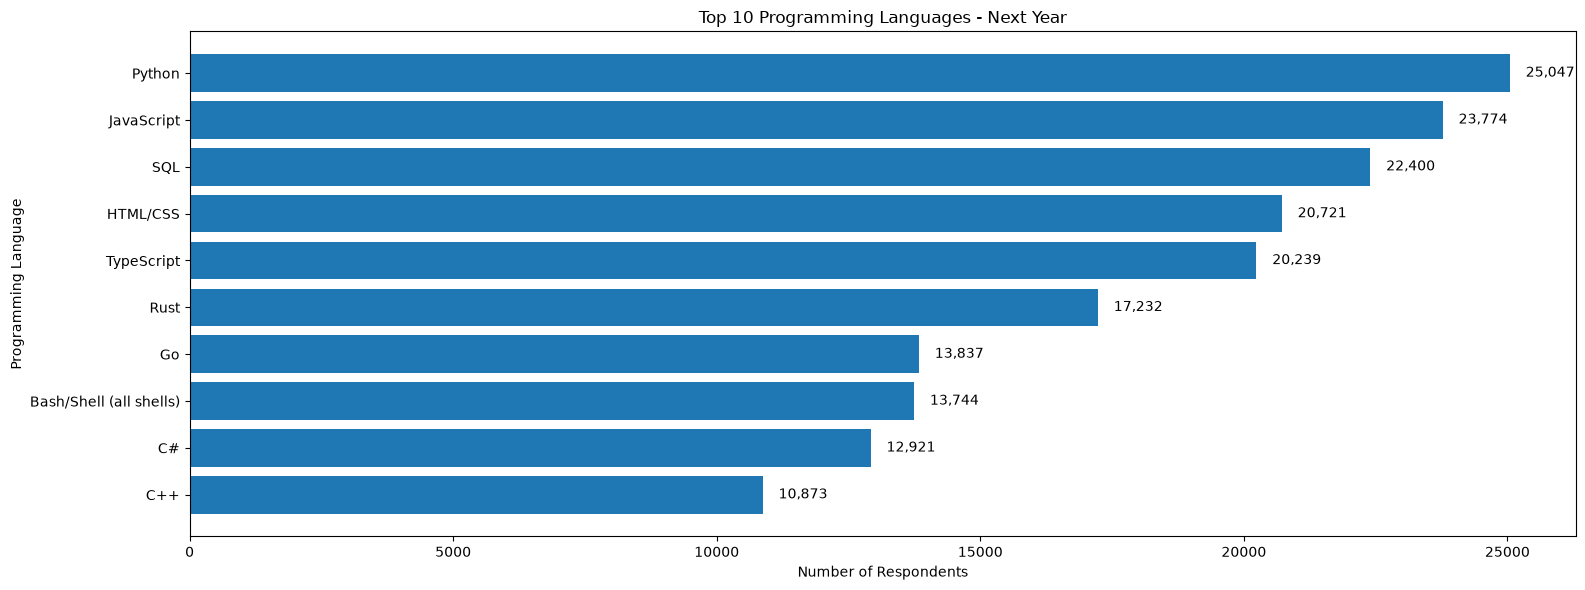

In [59]:
plt.figure(figsize=(16, 6))

bars = plt.barh(
    next_top10.index[::-1],
    next_top10.values[::-1]
)

plt.title("Top 10 Programming Languages - Next Year")
plt.xlabel("Number of Respondents")
plt.ylabel("Programming Language")

# Add data labels
for bar in bars:
    plt.text(
        bar.get_width() + 300,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width()):,}",
        va="center",
        ha="left"
    )

plt.tight_layout()
plt.show()

This lab demonstrates how to create and interpret different types of bar charts, allowing you to analyze the composition, comparison, and distribution of categorical data in the Stack Overflow dataset, including main professional branches, programming language preferences, and compensation by age group. Bar charts effectively compare counts and median values across various categories.


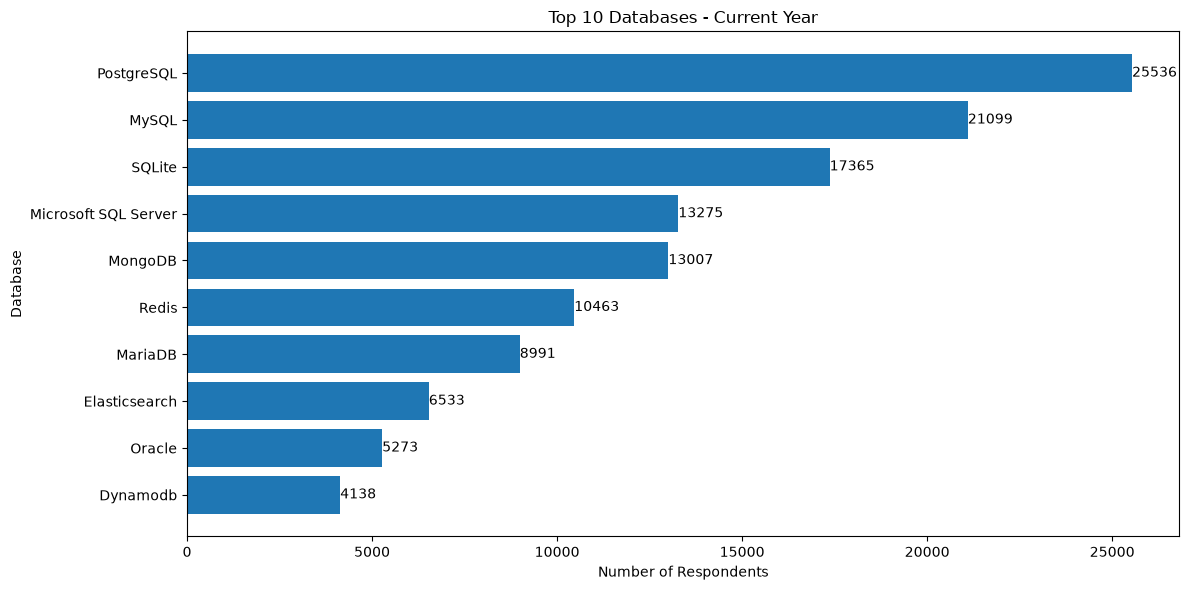

In [48]:


# Split multiple database answers and count them
current_db = (
    df["DatabaseHaveWorkedWith"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
    .sort_values()
)

# Plot
plt.figure(figsize=(12, 6))
bars = plt.barh(current_db.index, current_db.values)

plt.title("Top 10 Databases - Current Year")
plt.xlabel("Number of Respondents")
plt.ylabel("Database")

# Add value labels
for bar in bars:
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f"{int(bar.get_width())}",
        va="center",
        ha="left"
    )

plt.tight_layout()
plt.show()

In [50]:
# Create Next Year Top 10 database data

next_db = (
    df["DatabaseWantToWorkWith"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
    .sort_values()
)

print(next_db)

DatabaseWantToWorkWith
Supabase                 2930
Dynamodb                 3503
MariaDB                  5947
Elasticsearch            6246
Microsoft SQL Server     7905
Redis                   10847
MongoDB                 10982
MySQL                   12269
SQLite                  13489
PostgreSQL              24005
Name: count, dtype: int64

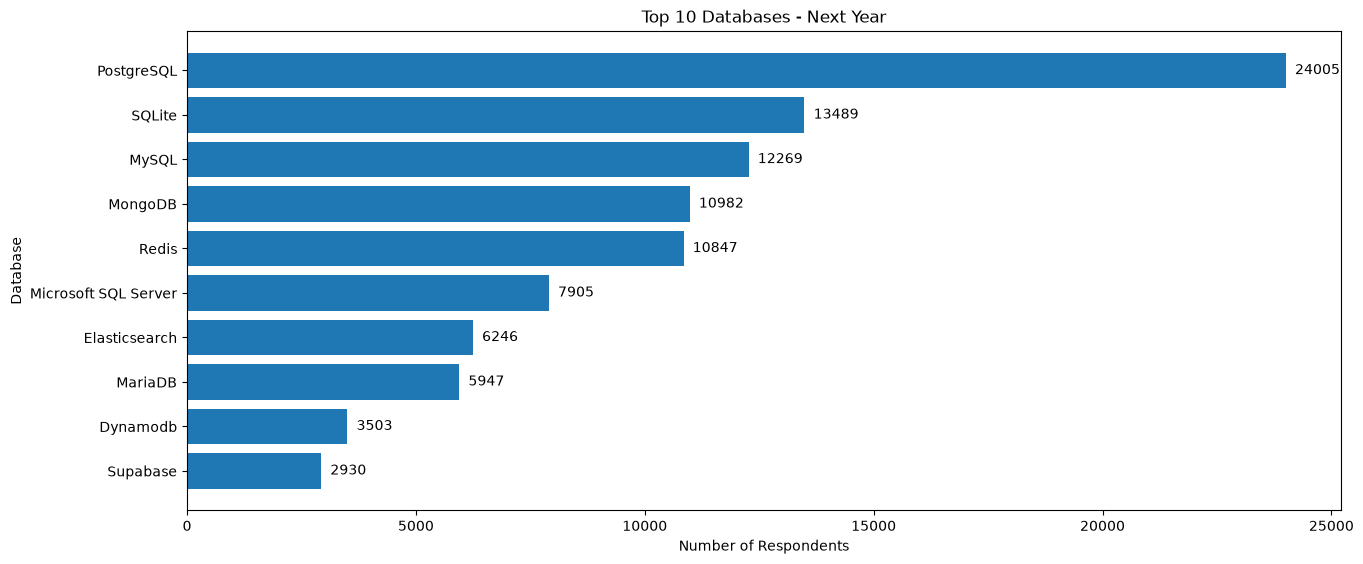

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
bars = plt.barh(next_db.index, next_db.values)

plt.title("Top 10 Databases - Next Year")
plt.xlabel("Number of Respondents")
plt.ylabel("Database")

for bar in bars:
    plt.text(
        bar.get_width() + 200,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center",
        ha="left"
    )

plt.tight_layout(pad=2)
plt.show()

## Summary


After completing this lab, you will be able to:
- Create a horizontal bar chart to visualize the distribution of respondents' primary roles, helping to understand their professional focus.
- Develop a vertical bar chart to identify the most desired programming languages based on the LanguageWantToWorkWith variable.
- Use a stacked bar chart to compare job satisfaction metrics across different age groups.
- Create a bar chart to visualize the most commonly used databases among respondents using the DatabaseHaveWorkedWith variable.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
